<a href="https://colab.research.google.com/github/BogguAjayKumar/House-Price-Predict/blob/main/_House_Price_Colab_Ready.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Practical 8: Predict a Numerical Value (House Price)
**Problem type:** Regression (the target is a continuous number)
**Dataset:** mock_house_data_10000.csv (10,000 synthetic records). Target `MedHouseVal` is in units of $100,000.

**Steps:** 1. Load & explore, 2. Visualise, 3. Preprocess & split, 4. Train models, 5. Evaluate, 6. Cross-validation, 7. Grid Search, 8. Interpret, 9. Save model

## 1. Load and explore the data

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Get the data
This cell needs **no upload**. If `mock_house_data_10000.csv` already exists it is loaded; otherwise the 10,000-row mock dataset is generated here (fixed random seed, so it is identical every run) and saved as a CSV.

In [ ]:
CSV = 'mock_house_data_10000.csv'

def make_mock_data(n=10000, seed=42):
    rng = np.random.default_rng(seed)
    ap = [
        ("LAX","Los Angeles International Airport","Los Angeles","California","USA",33.9425,-118.4081,.24,.7),
        ("SFO","San Francisco International Airport","San Francisco","California","USA",37.6213,-122.3790,.14,1.0),
        ("SAN","San Diego International Airport","San Diego","California","USA",32.7336,-117.1897,.10,.5),
        ("SJC","Norman Y. Mineta San Jose International Airport","San Jose","California","USA",37.3626,-121.9291,.08,.9),
        ("SMF","Sacramento International Airport","Sacramento","California","USA",38.6954,-121.5908,.07,0.0),
        ("OAK","Oakland International Airport","Oakland","California","USA",37.7213,-122.2208,.07,.5),
        ("LAS","Harry Reid International Airport","Las Vegas","Nevada","USA",36.0840,-115.1537,.06,-.1),
        ("PHX","Phoenix Sky Harbor International Airport","Phoenix","Arizona","USA",33.4343,-112.0116,.06,-.2),
        ("PDX","Portland International Airport","Portland","Oregon","USA",45.5887,-122.5975,.04,.2),
        ("SEA","Seattle-Tacoma International Airport","Seattle","Washington","USA",47.4502,-122.3088,.04,.6),
        ("YVR","Vancouver International Airport","Vancouver","British Columbia","Canada",49.1951,-123.1779,.02,.6),
        ("TIJ","General Abelardo L. Rodriguez International Airport","Tijuana","Baja California","Mexico",32.5411,-116.9702,.02,-.6),
    ]
    p = np.array([a[7] for a in ap]); p = p / p.sum()
    k = rng.choice(len(ap), n, p=p)
    alat = np.array([ap[i][5] for i in k]); alon = np.array([ap[i][6] for i in k])
    prem = np.array([ap[i][8] for i in k])
    latitude = alat + rng.normal(0, .25, n); longitude = alon + rng.normal(0, .25, n)
    dist = np.sqrt((latitude - alat)**2 + (longitude - alon)**2)

    MedInc = np.clip(rng.lognormal(1.25, .5, n), .5, 15)
    HouseAge = rng.integers(1, 53, n).astype(float)
    AveRooms = np.clip(rng.normal(5.4, 1.3, n) + .12*(MedInc - 3.9), 2, 12)
    AveBedrms = np.clip(AveRooms * rng.normal(.2, .03, n), .7, 3)
    Population = np.clip(rng.lognormal(7.1, .6, n), 5, 15000).round()
    AveOccup = np.clip(rng.normal(3, .8, n), 1, 8)
    price = (.3 + .35*MedInc + .04*MedInc**2 + .12*AveRooms - .15*AveOccup - .004*HouseAge
             + prem + .9*np.exp(-dist/.3) + rng.normal(0, .35, n))
    price = np.clip(price, .15, 5.0)

    return pd.DataFrame({
        "index": np.arange(n),
        "iata": [ap[i][0] for i in k], "name": [ap[i][1] for i in k],
        "city": [ap[i][2] for i in k], "state": [ap[i][3] for i in k], "country": [ap[i][4] for i in k],
        "latitude": latitude, "longitude": longitude,
        "MedInc": MedInc, "HouseAge": HouseAge, "AveRooms": AveRooms, "AveBedrms": AveBedrms,
        "Population": Population, "AveOccup": AveOccup, "MedHouseVal": price}).round(4)

if os.path.exists(CSV):
    df = pd.read_csv(CSV)
    print("Loaded existing", CSV)
else:
    df = make_mock_data()
    df.to_csv(CSV, index=False)
    print("Generated and saved", CSV)

df.head()

Generated and saved mock_house_data_10000.csv


,index,iata,name,city,state,country,latitude,longitude,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,MedHouseVal
0,0,LAS,Harry Reid International Airport,Las Vegas,Nevada,USA,35.6132,-114.8536,2.5557,40.0,7.2788,1.3454,581.0,2.9101,1.7470
1,1,SAN,San Diego International Airport,San Diego,California,USA,33.0162,-117.1014,2.7392,11.0,6.1661,1.3563,1837.0,2.6692,2.4587
2,2,PHX,Phoenix Sky Harbor International Airport,Phoenix,Arizona,USA,33.7300,-112.0342,1.7618,16.0,5.5453,0.9066,1329.0,3.2472,1.0671
3,3,OAK,Oakland International Airport,Oakland,California,USA,37.6027,-121.7869,3.4276,25.0,4.9375,1.1892,756.0,2.7489,2.6515
4,4,LAX,Los Angeles International Airport,Los Angeles,California,USA,34.0728,-118.4042,3.0522,19.0,4.2438,0.7294,960.0,2.2260,3.1194


## 1. Explore the data

In [ ]:
print("Shape:", df.shape)
df.info()
print("\nMissing values:\n", df.isnull().sum())
df.describe()

Shape: (10000, 15)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   index        10000 non-null  int64  
 1   iata         10000 non-null  object 
 2   name         10000 non-null  object 
 3   city         10000 non-null  object 
 4   state        10000 non-null  object 
 5   country      10000 non-null  object 
 6   latitude     10000 non-null  float64
 7   longitude    10000 non-null  float64
 8   MedInc       10000 non-null  float64
 9   HouseAge     10000 non-null  float64
 10  AveRooms     10000 non-null  float64
 11  AveBedrms    10000 non-null  float64
 12  Population   10000 non-null  float64
 13  AveOccup     10000 non-null  float64
 14  MedHouseVal  10000 non-null  float64
dtypes: float64(9), int64(1), object(5)
memory usage: 1.1+ MB

Missing values:
 index          0
iata           0
name           0
city           0
state      

,index,latitude,longitude,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,MedHouseVal
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,4999.50000,36.727020,-119.479401,3.943257,26.537600,5.385133,1.089244,1446.834300,2.999733,3.172208
std,2886.89568,4.083253,3.065941,2.091510,15.026788,1.311081,0.290945,958.729044,0.800176,1.151900
min,0.00000,31.871700,-123.853200,0.500000,1.000000,2.000000,0.700000,147.000000,1.000000,0.150000
25%,2499.75000,33.783775,-122.194525,2.486275,14.000000,4.497125,0.857675,810.750000,2.452750,2.310275
50%,4999.50000,36.277500,-118.811150,3.471100,27.000000,5.380250,1.060450,1199.000000,2.996000,3.039800
75%,7499.25000,37.796775,-117.639975,4.872675,40.000000,6.255825,1.272300,1818.250000,3.535350,4.058000
max,9999.00000,49.858200,-111.280700,15.000000,52.000000,10.571700,2.412800,13589.000000,5.984400,5.000000


## 2. Visualise

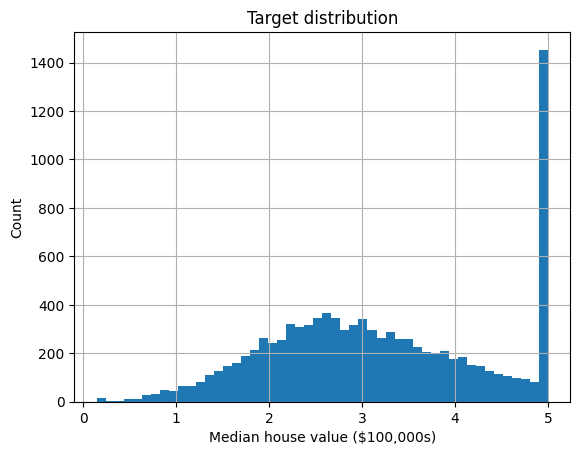

MedHouseVal    1.000000
MedInc         0.818581
AveRooms       0.275428
AveBedrms      0.220780
latitude       0.015566
Population     0.007850
index         -0.009142
HouseAge      -0.045368
AveOccup      -0.081083
longitude     -0.168215
Name: MedHouseVal, dtype: float64


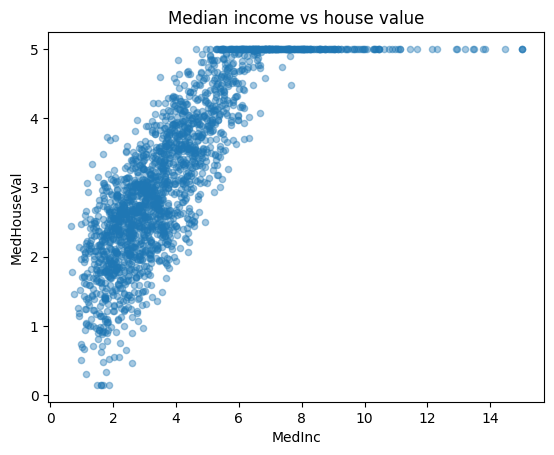

In [ ]:
# Distribution of the target
df['MedHouseVal'].hist(bins=50)
plt.xlabel('Median house value ($100,000s)'); plt.ylabel('Count'); plt.title('Target distribution')
plt.show()

# Correlation of each feature with price
print(df.corr(numeric_only=True)['MedHouseVal'].sort_values(ascending=False))

# Strongest feature vs price
df.sample(2000, random_state=1).plot.scatter(x='MedInc', y='MedHouseVal', alpha=0.4)
plt.title('Median income vs house value'); plt.show()

## 3. Preprocess and split
Text columns are one-hot encoded, and unneeded columns are dropped. There are no missing values, so no cleaning is needed. Scaling is applied inside pipelines for the models that need it. The test set stays untouched until evaluation.

In [ ]:
from sklearn.model_selection import train_test_split

# 'index' is just a row number; 'iata' and 'name' repeat the information in 'city', so we drop them
X = df.drop(columns=['MedHouseVal', 'index', 'iata', 'name'])
y = df['MedHouseVal']

# Encode text columns (city, state, country) as 0/1 columns
X = pd.get_dummies(X, columns=['city', 'state', 'country'], dtype=int)
print(X.shape)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape)

(10000, 30)
(8000, 30) (2000, 30)


## 4. Train regression models

In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor

models = {
    "Linear Regression": make_pipeline(StandardScaler(), LinearRegression()),
    "KNN Regressor":     make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=5)),
    "Decision Tree":     DecisionTreeRegressor(max_depth=8, random_state=42),
    "Random Forest":     RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1),
}

for name, m in models.items():
    m.fit(X_train, y_train)
print("All models trained.")

All models trained.


## 5. Evaluate with regression metrics
- **MAE**: average absolute error
- **RMSE**: penalises large errors more
- **R²**: fraction of variance explained (closer to 1 is better)

Comparing train R² and test R² helps detect overfitting.

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

rows = []
preds = {}
for name, m in models.items():
    p = m.predict(X_test)
    preds[name] = p
    rows.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, p),
        "RMSE": np.sqrt(mean_squared_error(y_test, p)),
        "R2 (test)": r2_score(y_test, p),
        "R2 (train)": r2_score(y_train, m.predict(X_train)),
    })
results = pd.DataFrame(rows).set_index("Model").round(3).sort_values("R2 (test)", ascending=False)
results

,MAE,RMSE,R2 (test),R2 (train)
Model,,,,
Random Forest,0.277,0.365,0.897,0.985
Decision Tree,0.329,0.438,0.851,0.887
KNN Regressor,0.393,0.509,0.800,0.873
Linear Regression,0.392,0.529,0.784,0.795


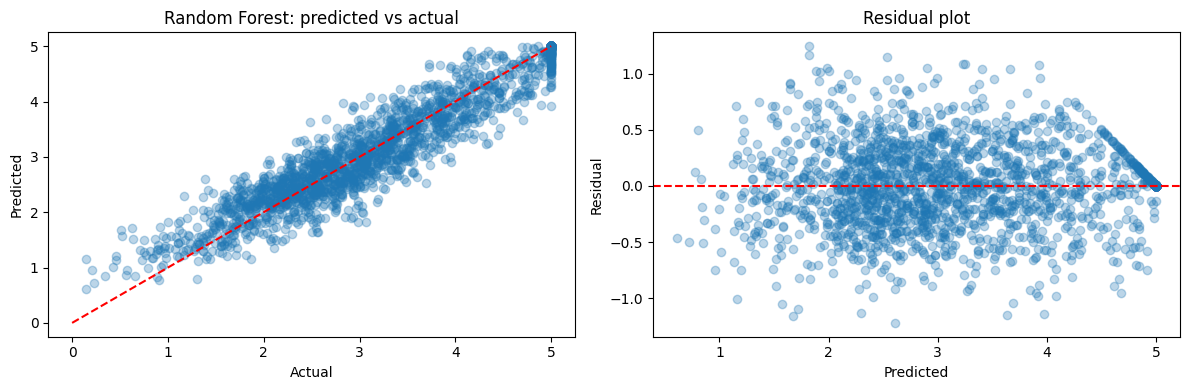

In [ ]:
# Predicted vs actual, and residuals, for the best model
best_name = results.index[0]
p = preds[best_name]

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].scatter(y_test, p, alpha=0.3)
ax[0].plot([0, 5], [0, 5], 'r--')
ax[0].set_xlabel('Actual'); ax[0].set_ylabel('Predicted'); ax[0].set_title(f'{best_name}: predicted vs actual')

ax[1].scatter(p, y_test - p, alpha=0.3)
ax[1].axhline(0, color='r', linestyle='--')
ax[1].set_xlabel('Predicted'); ax[1].set_ylabel('Residual'); ax[1].set_title('Residual plot')
plt.tight_layout(); plt.show()

## 6. K-fold cross-validation

In [ ]:
from sklearn.model_selection import cross_val_score

for name, m in models.items():
    scores = cross_val_score(m, X_train, y_train, cv=5, scoring='r2')
    print(f"{name:20s} mean R2 = {scores.mean():.3f}  (+/- {scores.std():.3f})")

Linear Regression    mean R2 = 0.793  (+/- 0.017)
KNN Regressor        mean R2 = 0.801  (+/- 0.006)
Decision Tree        mean R2 = 0.845  (+/- 0.012)
Random Forest        mean R2 = 0.891  (+/- 0.006)


## 7. Hyperparameter tuning with GridSearchCV
This may take a minute or two on Colab.

In [ ]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "n_estimators": [50, 100],
    "max_depth": [10, 20, None],
}
grid = GridSearchCV(
    RandomForestRegressor(random_state=42, n_jobs=-1),
    param_grid, cv=3, scoring='r2'
)
grid.fit(X_train, y_train)

print("Best parameters:", grid.best_params_)
print("Best CV R2:", round(grid.best_score_, 3))

best_model = grid.best_estimator_
p = best_model.predict(X_test)
print("Test MAE :", round(mean_absolute_error(y_test, p), 3))
print("Test RMSE:", round(np.sqrt(mean_squared_error(y_test, p)), 3))
print("Test R2  :", round(r2_score(y_test, p), 3))

Best parameters: {'max_depth': 20, 'n_estimators': 100}
Best CV R2: 0.891
Test MAE : 0.276
Test RMSE: 0.365
Test R2  : 0.897


## 8. Interpret: which features drive price?

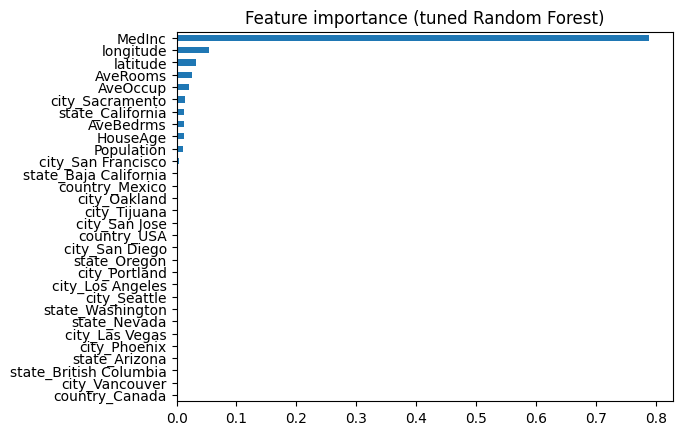

In [ ]:
imp = pd.Series(best_model.feature_importances_, index=X.columns).sort_values()
imp.plot.barh()
plt.title('Feature importance (tuned Random Forest)'); plt.show()

## 9. Save the model and try a prediction

In [ ]:
import joblib
joblib.dump(best_model, 'house_price_model.joblib')

loaded = joblib.load('house_price_model.joblib')
sample = X_test.iloc[[0]]
print("Predicted:", round(loaded.predict(sample)[0] * 100000), "USD")
print("Actual   :", round(y_test.iloc[0] * 100000), "USD")

# Uncomment to download the model file to your computer:
# from google.colab import files
# files.download('house_price_model.joblib')

Predicted: 296330 USD
Actual   : 321970 USD


## Conclusion (edit for your report)
- This is a **regression** problem, since the target is a continuous value.
- Linear Regression gives a baseline; tree-based models capture non-linear patterns better.
- The best model was chosen using R², MAE and RMSE on held-out test data, and validated with 5-fold cross-validation.
- Median income was the most influential feature, followed by location.